# 04 Advanced Models — Phase 1: Rigorous Ranking Evaluation

This notebook does **not** change notebooks 01–03. It re-scores the same three models
(Popularity, Item-CF, SVD) with a documented ranking protocol that also reports **NDCG@10**,
and runs a train/test **leakage check**.

**Protocol**
- Relevant: test rating ≥ 4.0
- Candidates: catalog movies the user did **not** rate in train
- Users evaluated: users with ≥ 1 relevant test item (and a train row)
- Metrics: Precision@10, Recall@10, NDCG@10 (plus RMSE for rating prediction)

In [1]:
import numpy as np
import pandas as pd
import utils

SEED = 42
np.random.seed(SEED)

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
M = utils.build_user_item(train)
print("matrix:", M.shape)
print("train rows:", len(train), "| test rows:", len(test))

matrix: (610, 2000)
train rows: 62711 | test rows: 15594


## 1. Toy NDCG sanity check

Binary gains, ranks start at 1. Ideal places all relevant items first.

In [2]:
# Ranking: relevant, miss, relevant  → gains [1, 0, 1]
dcg = utils._dcg_at_k([1, 0, 1], k=3)
idcg = utils._dcg_at_k([1, 1], k=3)  # two relevant items ideally first
ndcg = dcg / idcg
expected_dcg = 1.0 / np.log2(2) + 0.0 / np.log2(3) + 1.0 / np.log2(4)
expected_idcg = 1.0 / np.log2(2) + 1.0 / np.log2(3)
assert np.isclose(dcg, expected_dcg)
assert np.isclose(idcg, expected_idcg)
assert np.isclose(ndcg, expected_dcg / expected_idcg)
print(f"toy NDCG@3 = {ndcg:.6f}  (PASS)")

toy NDCG@3 = 0.919721  (PASS)


## 2. Leakage check

Confirm no (user, movie) pair is in both train and test, and that no test cell is
already filled in the train matrix that item means / SVD fit on.

In [3]:
leak = utils.leakage_check(train, test, M)
assert leak["passed"], "Leakage detected — stop and inspect the split."

leakage_check: PASS | overlap_pairs=0 | test_cells_filled_in_train_matrix=0


## 3. Fit the three existing models (same as notebook 03)

No retuning. SVD uses `random_state=42`.

In [4]:
pop = utils.PopularityBaseline().fit(M)
cf = utils.ItemBasedCF().fit(M)
svd = utils.SVDRecommender().fit(M, n_components=20, seed=SEED)
models = {"Popularity": pop, "Item-CF": cf, "SVD": svd}
print("fitted: popularity, item-CF, SVD(20 factors)")

fitted: popularity, item-CF, SVD(20 factors)


## 4. Evaluate with the Phase 1 ranking protocol

README baselines (from notebook 03, for side-by-side comparison):

| Model | RMSE ↓ | Precision@10 ↑ | Recall@10 ↑ |
|---|---|---|---|
| Popularity | 0.9381 | 0.0146 | 0.0119 |
| Item-based CF | 0.8298 | 0.0262 | 0.0107 |
| SVD (20 factors) | 0.8918 | 0.1293 | 0.1200 |

In [5]:
README = {
    "Popularity": {"RMSE": 0.9381, "P@10": 0.0146, "R@10": 0.0119},
    "Item-CF":    {"RMSE": 0.8298, "P@10": 0.0262, "R@10": 0.0107},
    "SVD":        {"RMSE": 0.8918, "P@10": 0.1293, "R@10": 0.1200},
}

rows = []
proto = None
for name, model in models.items():
    rmse = utils.rmse_on_test(model, test)
    rank = utils.ranking_metrics_at_k(model, M, test, k=10, rel_threshold=4.0)
    if proto is None:
        proto = rank
    rows.append({
        "model": name,
        "RMSE": round(rmse, 4),
        "P@10": round(rank["precision@k"], 4),
        "R@10": round(rank["recall@k"], 4),
        "NDCG@10": round(rank["ndcg@k"], 4),
        "n_users": rank["n_users_evaluated"],
        "README_RMSE": README[name]["RMSE"],
        "README_P@10": README[name]["P@10"],
        "README_R@10": README[name]["R@10"],
    })

results = pd.DataFrame(rows)
print("Evaluation protocol")
print(f"  rel_threshold = {proto['rel_threshold']}")
print("  candidates    = train_matrix columns minus movies the user rated in train")
print(f"  n_users_evaluated = {proto['n_users_evaluated']}")
print(f"  n_users_skipped   = {proto['n_users_skipped']}  (relevant test items but no train row)")
print()
display(results)

Evaluation protocol
  rel_threshold = 4.0
  candidates    = train_matrix columns minus movies the user rated in train
  n_users_evaluated = 591
  n_users_skipped   = 0  (relevant test items but no train row)



,model,RMSE,P@10,R@10,NDCG@10,n_users,README_RMSE,README_P@10,README_R@10
0,Popularity,0.9381,0.0146,0.0119,0.0148,591,0.9381,0.0146,0.0119
1,Item-CF,0.8298,0.0262,0.0107,0.0250,591,0.8298,0.0262,0.0107
2,SVD,0.8918,0.1293,0.1200,0.1755,591,0.8918,0.1293,0.1200


## 5. Notes on any README differences

If P@10 / R@10 match the README, the Phase 1 evaluator uses the same relevance threshold
and candidate set as `precision_recall_at_k` in notebook 03. NDCG@10 is new.
If numbers differ, the cause is one of: threshold, candidate set, or score-tie order —
document that here after running; do not rewrite the README in Phase 1.

---
# Phase 2: Content-based model with embeddings

Embed each of the 2,000 catalog movies (`title + genres`) with
`all-MiniLM-L6-v2`, build a **rating-weighted** user profile from train likes
(rating ≥ 4.0), and rank unseen movies by cosine similarity.

Embeddings are cached to `data/item_embeddings_minilm.npz` so re-runs are fast.
Evaluated with the same Phase 1 protocol (no test-set tuning).

In [6]:
# Cold-kernel safety: rebuild train matrix / CF models if needed
import numpy as np
import pandas as pd
import utils

SEED = 42
np.random.seed(SEED)

if "M" not in globals():
    train = pd.read_csv("data/train.csv")
    test = pd.read_csv("data/test.csv")
    M = utils.build_user_item(train)

if "models" not in globals():
    pop = utils.PopularityBaseline().fit(M)
    cf = utils.ItemBasedCF().fit(M)
    svd = utils.SVDRecommender().fit(M, n_components=20, seed=SEED)
    models = {"Popularity": pop, "Item-CF": cf, "SVD": svd}

print("matrix:", M.shape, "| models ready:", list(models))

matrix: (610, 2000) | models ready: ['Popularity', 'Item-CF', 'SVD']


## 6. Build movie texts and MiniLM embeddings

In [7]:
meta = utils.load_movie_metadata("data/movies.csv")
item_ids = list(M.columns)
texts = utils.build_item_texts(meta, item_ids)
print("example text:", texts[0])
print("n_texts:", len(texts))

item_emb = utils.load_or_compute_item_embeddings(
    item_ids,
    texts,
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    cache_path="data/item_embeddings_minilm.npz",
    seed=SEED,
)
print("embeddings shape:", item_emb.shape)

example text: Toy Story (1995). Genres: Adventure, Animation, Children, Comedy, Fantasy
n_texts: 2000
embeddings cache HIT: data\item_embeddings_minilm.npz  shape=(2000, 384)
embeddings shape: (2000, 384)


## 7. Fit content-based recommender

User profile = rating-weighted mean of embeddings for train movies rated ≥ 4.0.
Fallback: mean of all train-rated embeddings; else catalog mean.

In [8]:
content = utils.ContentEmbeddingRecommender().fit(
    M, item_emb, rel_threshold=4.0
)
models["Content-Emb"] = content
print("fitted ContentEmbeddingRecommender; n_profiles:", len(content.profiles))

fitted ContentEmbeddingRecommender; n_profiles: 610


## 8. Evaluate all four models (Phase 1 protocol)

In [9]:
rows = []
proto = None
for name, model in models.items():
    print("scoring", name, "...")
    rmse = utils.rmse_on_test(model, test)
    rank = utils.ranking_metrics_at_k(model, M, test, k=10, rel_threshold=4.0)
    if proto is None:
        proto = rank
    rows.append({
        "model": name,
        "RMSE": round(rmse, 4),
        "P@10": round(rank["precision@k"], 4),
        "R@10": round(rank["recall@k"], 4),
        "NDCG@10": round(rank["ndcg@k"], 4),
        "n_users": rank["n_users_evaluated"],
    })

phase2_results = pd.DataFrame(rows)
print()
print("Evaluation protocol (unchanged from Phase 1)")
print(f"  rel_threshold = {proto['rel_threshold']}")
print("  candidates    = train_matrix columns minus movies the user rated in train")
print(f"  n_users_evaluated = {proto['n_users_evaluated']}")
print()
display(phase2_results)

scoring Popularity ...


scoring Item-CF ...


scoring SVD ...


scoring Content-Emb ...



Evaluation protocol (unchanged from Phase 1)
  rel_threshold = 4.0
  candidates    = train_matrix columns minus movies the user rated in train
  n_users_evaluated = 591



,model,RMSE,P@10,R@10,NDCG@10,n_users
0,Popularity,0.9381,0.0146,0.0119,0.0148,591
1,Item-CF,0.8298,0.0262,0.0107,0.0250,591
2,SVD,0.8918,0.1293,0.1200,0.1755,591
3,Content-Emb,1.1465,0.0394,0.0427,0.0487,591


## 9. Honest takeaway

Compare **Content-Emb** ranking metrics to **SVD**. If Content does not beat SVD on
P@10 / R@10 / NDCG@10, that is a valid result — title+genres text is thin signal
compared with collaborative patterns. Do **not** tune on the test set.

In [10]:
base = phase2_results.set_index("model")
content_row = base.loc["Content-Emb"]
svd_row = base.loc["SVD"]
beats = {
    "P@10": content_row["P@10"] > svd_row["P@10"],
    "R@10": content_row["R@10"] > svd_row["R@10"],
    "NDCG@10": content_row["NDCG@10"] > svd_row["NDCG@10"],
}
print("Content-Emb vs SVD")
print(f"  Content  P@10={content_row['P@10']:.4f}  R@10={content_row['R@10']:.4f}  NDCG@10={content_row['NDCG@10']:.4f}")
print(f"  SVD      P@10={svd_row['P@10']:.4f}  R@10={svd_row['R@10']:.4f}  NDCG@10={svd_row['NDCG@10']:.4f}")
print("  beats SVD?", beats)
if not any(beats.values()):
    print("  Content-Emb does not beat SVD on ranking metrics (reported honestly; no test tuning).")
elif all(beats.values()):
    print("  Content-Emb beats SVD on all ranking metrics.")
else:
    print("  Content-Emb beats SVD on some ranking metrics only.")

Content-Emb vs SVD
  Content  P@10=0.0394  R@10=0.0427  NDCG@10=0.0487
  SVD      P@10=0.1293  R@10=0.1200  NDCG@10=0.1755
  beats SVD? {'P@10': np.False_, 'R@10': np.False_, 'NDCG@10': np.False_}
  Content-Emb does not beat SVD on ranking metrics (reported honestly; no test tuning).


---
# Phase 3: Hybrid SVD + content

Blend per-user min-max-normalised scores:
`score = α · SVD + (1 − α) · Content`.

**α is chosen on a validation split carved from TRAIN only** (never test),
maximising NDCG@10 over `α ∈ {0.0, 0.1, …, 1.0}`. Then refit on full train
and evaluate the chosen α once on test.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import utils

SEED = 42
np.random.seed(SEED)

if "train" not in globals() or "M" not in globals():
    train = pd.read_csv("data/train.csv")
    test = pd.read_csv("data/test.csv")
    M = utils.build_user_item(train)

if "item_emb" not in globals():
    meta = utils.load_movie_metadata("data/movies.csv")
    item_ids = list(M.columns)
    texts = utils.build_item_texts(meta, item_ids)
    item_emb = utils.load_or_compute_item_embeddings(
        item_ids, texts, cache_path="data/item_embeddings_minilm.npz", seed=SEED
    )
else:
    item_ids = list(M.columns)

print("matrix:", M.shape, "| embeddings:", item_emb.shape)

matrix: (610, 2000) | embeddings: (2000, 384)


## 10. Select α on train-only validation (NDCG@10)

In [12]:
alphas = np.linspace(0.0, 1.0, 11)
sel = utils.select_hybrid_alpha(
    train,
    item_emb,
    item_ids=item_ids,
    alphas=alphas,
    k=10,
    rel_threshold=4.0,
    val_size=0.2,
    seed=SEED,
    n_components=20,
)
best_alpha = sel["best_alpha"]
val_curve = sel["val_curve"]
print(f"fit rows={sel['n_fit']} | val rows={sel['n_val']}")
display(val_curve.round(4))

select_hybrid_alpha: best_alpha=0.6 | val NDCG@10=0.1327 | val P@10=0.0842 | n_val_users=583
fit rows=50215 | val rows=12496


,alpha,P@10,R@10,NDCG@10,n_users
0,0.0,0.0259,0.0378,0.0393,583
1,0.1,0.0314,0.0477,0.0488,583
2,0.2,0.0395,0.0630,0.0648,583
3,0.3,0.0501,0.0801,0.0867,583
4,0.4,0.0659,0.0991,0.1106,583
5,0.5,0.0775,0.1099,0.1259,583
6,0.6,0.0842,0.1152,0.1327,583
7,0.7,0.0844,0.1148,0.1288,583
8,0.8,0.0858,0.1129,0.1262,583
9,0.9,0.0823,0.1083,0.1196,583


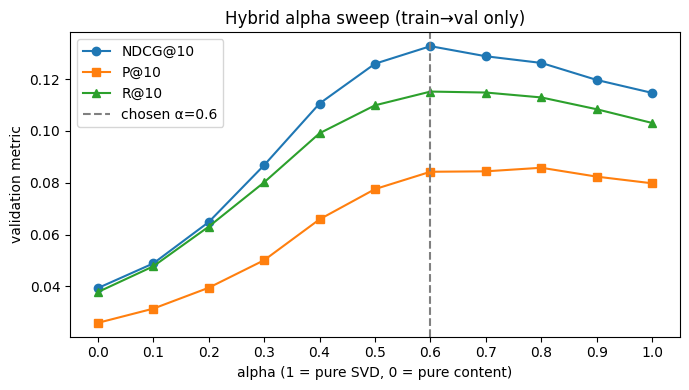

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(val_curve["alpha"], val_curve["NDCG@10"], marker="o", label="NDCG@10")
ax.plot(val_curve["alpha"], val_curve["P@10"], marker="s", label="P@10")
ax.plot(val_curve["alpha"], val_curve["R@10"], marker="^", label="R@10")
ax.axvline(best_alpha, color="gray", ls="--", label=f"chosen α={best_alpha:.1f}")
ax.set_xlabel("alpha (1 = pure SVD, 0 = pure content)")
ax.set_ylabel("validation metric")
ax.set_title("Hybrid alpha sweep (train→val only)")
ax.legend()
ax.set_xticks(alphas)
plt.tight_layout()
plt.show()

## 11. Refit on full train, evaluate Hybrid once on test

Ranking metrics decide quality. Hybrid RMSE blends raw predicts and is secondary.

In [14]:
# Ensure base models on full train
if "models" not in globals() or "SVD" not in models or "Content-Emb" not in models:
    pop = utils.PopularityBaseline().fit(M)
    cf = utils.ItemBasedCF().fit(M)
    svd = utils.SVDRecommender().fit(M, n_components=20, seed=SEED)
    content = utils.ContentEmbeddingRecommender().fit(M, item_emb, rel_threshold=4.0)
    models = {
        "Popularity": pop,
        "Item-CF": cf,
        "SVD": svd,
        "Content-Emb": content,
    }
else:
    svd = models["SVD"]
    content = models["Content-Emb"]

hybrid = utils.HybridRecommender(svd, content, alpha=best_alpha)
hybrid_name = f"Hybrid(α={best_alpha:.1f})"
models[hybrid_name] = hybrid
print("built", hybrid_name)

built Hybrid(α=0.6)


In [15]:
rows = []
for name, model in models.items():
    print("scoring", name, "...")
    rmse = utils.rmse_on_test(model, test)
    rank = utils.ranking_metrics_at_k(model, M, test, k=10, rel_threshold=4.0)
    rows.append({
        "model": name,
        "RMSE": round(rmse, 4),
        "P@10": round(rank["precision@k"], 4),
        "R@10": round(rank["recall@k"], 4),
        "NDCG@10": round(rank["ndcg@k"], 4),
        "n_users": rank["n_users_evaluated"],
    })

phase3_results = pd.DataFrame(rows)
print()
print("Test evaluation (α chosen on train-val only; not retuned on test)")
display(phase3_results)

scoring Popularity ...


scoring Item-CF ...


scoring SVD ...


scoring Content-Emb ...


scoring Hybrid(α=0.6) ...



Test evaluation (α chosen on train-val only; not retuned on test)


,model,RMSE,P@10,R@10,NDCG@10,n_users
0,Popularity,0.9381,0.0146,0.0119,0.0148,591
1,Item-CF,0.8298,0.0262,0.0107,0.0250,591
2,SVD,0.8918,0.1293,0.1200,0.1755,591
3,Content-Emb,1.1465,0.0394,0.0427,0.0487,591
4,Hybrid(α=0.6),0.9446,0.1293,0.1293,0.1843,591


## 12. Honest takeaway — Hybrid vs SVD

In [16]:
base = phase3_results.set_index("model")
h = base.loc[hybrid_name]
s = base.loc["SVD"]
c = base.loc["Content-Emb"]
beats_svd = {
    "P@10": bool(h["P@10"] > s["P@10"]),
    "R@10": bool(h["R@10"] > s["R@10"]),
    "NDCG@10": bool(h["NDCG@10"] > s["NDCG@10"]),
}
print(f"{hybrid_name} vs SVD vs Content-Emb (test)")
print(f"  Hybrid   P@10={h['P@10']:.4f}  R@10={h['R@10']:.4f}  NDCG@10={h['NDCG@10']:.4f}")
print(f"  SVD      P@10={s['P@10']:.4f}  R@10={s['R@10']:.4f}  NDCG@10={s['NDCG@10']:.4f}")
print(f"  Content  P@10={c['P@10']:.4f}  R@10={c['R@10']:.4f}  NDCG@10={c['NDCG@10']:.4f}")
print("  Hybrid beats SVD?", beats_svd)
if not any(beats_svd.values()):
    print("  Hybrid does not beat SVD on ranking (reported honestly; α not retuned on test).")
elif all(beats_svd.values()):
    print("  Hybrid beats SVD on all ranking metrics.")
else:
    print("  Hybrid beats SVD on some ranking metrics only.")

Hybrid(α=0.6) vs SVD vs Content-Emb (test)
  Hybrid   P@10=0.1293  R@10=0.1293  NDCG@10=0.1843
  SVD      P@10=0.1293  R@10=0.1200  NDCG@10=0.1755
  Content  P@10=0.0394  R@10=0.0427  NDCG@10=0.0487
  Hybrid beats SVD? {'P@10': False, 'R@10': True, 'NDCG@10': True}
  Hybrid beats SVD on some ranking metrics only.


---
# Phase 4: Activity and cold-start analysis

Break ranking metrics down by **train activity tertiles** (light / medium / heavy)
and a **cold-start** bucket (≤ 20 train ratings). Focus: do Content or Hybrid(α=0.6)
help sparse users more than SVD?

Same Phase 1 protocol. α is fixed from Phase 3 (not re-swept).

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import utils

SEED = 42
BEST_ALPHA = 0.6  # from Phase 3 train-val selection
np.random.seed(SEED)

if "train" not in globals() or "M" not in globals():
    train = pd.read_csv("data/train.csv")
    test = pd.read_csv("data/test.csv")
    M = utils.build_user_item(train)

if "item_emb" not in globals():
    meta = utils.load_movie_metadata("data/movies.csv")
    item_ids = list(M.columns)
    texts = utils.build_item_texts(meta, item_ids)
    item_emb = utils.load_or_compute_item_embeddings(
        item_ids, texts, cache_path="data/item_embeddings_minilm.npz", seed=SEED
    )

need = ("models" not in globals()
        or "SVD" not in models
        or "Content-Emb" not in models
        or not any(str(k).startswith("Hybrid") for k in models))
if need:
    pop = utils.PopularityBaseline().fit(M)
    svd = utils.SVDRecommender().fit(M, n_components=20, seed=SEED)
    content = utils.ContentEmbeddingRecommender().fit(M, item_emb, rel_threshold=4.0)
    hybrid = utils.HybridRecommender(svd, content, alpha=BEST_ALPHA)
    models = {
        "Popularity": pop,
        "SVD": svd,
        "Content-Emb": content,
        f"Hybrid(α={BEST_ALPHA:.1f})": hybrid,
    }

analysis_models = {
    k: models[k]
    for k in models
    if k in ("Popularity", "SVD", "Content-Emb") or str(k).startswith("Hybrid")
}
print("analysis models:", list(analysis_models))

analysis models: ['Popularity', 'SVD', 'Content-Emb', 'Hybrid(α=0.6)']


## 13. Per-user metrics + activity tertiles

In [18]:
activity = utils.train_activity_counts(train)
print(
    f"train activity: min={activity.min()} median={activity.median():.0f} "
    f"max={activity.max()} | n≤10={(activity <= 10).sum()} | n≤20={(activity <= 20).sum()}"
)

per_user_frames = []
for name, model in analysis_models.items():
    print("per-user ranking:", name, "...")
    df = utils.per_user_ranking_at_k(model, M, test, k=10, rel_threshold=4.0)
    df["model"] = name
    df["n_train"] = df["user"].map(activity)
    per_user_frames.append(df)

per_user = pd.concat(per_user_frames, ignore_index=True)
eval_users = sorted(per_user["user"].unique())
tert = utils.assign_activity_tertiles(activity, eval_users)
per_user["activity"] = per_user["user"].map(tert["labels"])
print("evaluated users:", len(eval_users))
display(per_user.head())

train activity: min=6 median=50 max=1216 | n≤10=5 | n≤20=98
per-user ranking: Popularity ...


per-user ranking: SVD ...


per-user ranking: Content-Emb ...


per-user ranking: Hybrid(α=0.6) ...


activity tertiles: light ≤ 33 | medium ≤ 91 | heavy > 91 | n={'light': np.int64(203), 'medium': np.int64(192), 'heavy': np.int64(196)}
evaluated users: 591


,user,precision@k,recall@k,ndcg@k,model,n_train,activity
0,1,0.0,0.0,0.0,Popularity,157,heavy
1,2,0.0,0.0,0.0,Popularity,20,light
2,3,0.0,0.0,0.0,Popularity,20,light
3,4,0.0,0.0,0.0,Popularity,136,heavy
4,5,0.0,0.0,0.0,Popularity,30,light


Metrics by train-activity tertile


,model,activity,P10,R10,NDCG10,n_users
0,Content-Emb,light,0.0222,0.0601,0.0408,203
1,Content-Emb,medium,0.0318,0.0427,0.0403,192
2,Content-Emb,heavy,0.0648,0.0247,0.0651,196
3,Hybrid(α=0.6),light,0.0571,0.1522,0.1230,203
4,Hybrid(α=0.6),medium,0.1104,0.1400,0.1629,192
5,Hybrid(α=0.6),heavy,0.2224,0.0952,0.2686,196
6,Popularity,light,0.0039,0.0104,0.0064,203
7,Popularity,medium,0.0135,0.0156,0.0131,192
8,Popularity,heavy,0.0265,0.0098,0.0250,196
9,SVD,light,0.0512,0.1393,0.1044,203


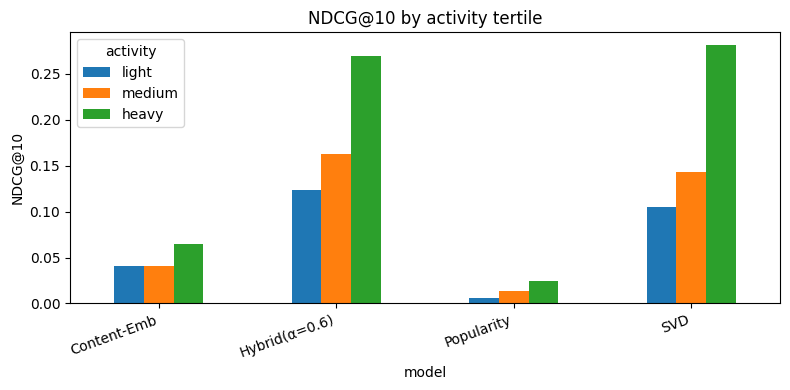

In [19]:
activity_table = (
    per_user.groupby(["model", "activity"], observed=True)
    .agg(
        P10=("precision@k", "mean"),
        R10=("recall@k", "mean"),
        NDCG10=("ndcg@k", "mean"),
        n_users=("user", "nunique"),
    )
    .reset_index()
)
activity_table[["P10", "R10", "NDCG10"]] = activity_table[["P10", "R10", "NDCG10"]].round(4)
print("Metrics by train-activity tertile")
display(activity_table)

pivot_ndcg = activity_table.pivot(index="model", columns="activity", values="NDCG10")
ax = pivot_ndcg.plot(kind="bar", figsize=(8, 4))
ax.set_ylabel("NDCG@10")
ax.set_title("NDCG@10 by activity tertile")
ax.legend(title="activity")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 14. Cold-start check (≤ 20 train ratings)

In [20]:
cold = per_user[per_user["n_train"] <= 20].copy()
n_cold = cold["user"].nunique()
n_le10 = per_user.loc[per_user["n_train"] <= 10, "user"].nunique()
print(f"cold-start evaluated users (n_train≤20): {n_cold} | context n_train≤10: {n_le10}")

def _summarise(df, label):
    g = (
        df.groupby("model")
        .agg(
            P10=("precision@k", "mean"),
            R10=("recall@k", "mean"),
            NDCG10=("ndcg@k", "mean"),
            n_users=("user", "nunique"),
        )
        .reset_index()
    )
    g[["P10", "R10", "NDCG10"]] = g[["P10", "R10", "NDCG10"]].round(4)
    g.insert(0, "cohort", label)
    return g

cold_table = pd.concat(
    [_summarise(cold, "cold≤20"), _summarise(per_user, "overall")],
    ignore_index=True,
)
display(cold_table)

cold-start evaluated users (n_train≤20): 84 | context n_train≤10: 4


,cohort,model,P10,R10,NDCG10,n_users
0,cold≤20,Content-Emb,0.0179,0.0537,0.0394,84
1,cold≤20,Hybrid(α=0.6),0.0429,0.1268,0.0971,84
2,cold≤20,Popularity,0.0036,0.0083,0.0061,84
3,cold≤20,SVD,0.0393,0.1104,0.0749,84
4,overall,Content-Emb,0.0394,0.0427,0.0487,591
5,overall,Hybrid(α=0.6),0.1293,0.1293,0.1843,591
6,overall,Popularity,0.0146,0.0119,0.0148,591
7,overall,SVD,0.1293,0.1200,0.1755,591


## 15. Verdict (from measured numbers only)

In [21]:
def _ndcg(table, model, activity=None):
    if activity is None:
        row = table[table["model"] == model].iloc[0]
    else:
        row = table[(table["model"] == model) & (table["activity"] == activity)].iloc[0]
    return float(row["NDCG10"]), float(row["R10"]), int(row["n_users"])

hybrid_name = [k for k in analysis_models if str(k).startswith("Hybrid")][0]

print("Light users (sparse)")
for m in ["SVD", "Content-Emb", hybrid_name]:
    nd, r, n = _ndcg(activity_table, m, "light")
    print(f"  {m}: NDCG@10={nd:.4f}  R@10={r:.4f}  n={n}")

print("Cold-start (n_train≤20)")
cold_only = cold_table[cold_table["cohort"] == "cold≤20"]
for m in ["SVD", "Content-Emb", hybrid_name]:
    row = cold_only[cold_only["model"] == m].iloc[0]
    print(f"  {m}: NDCG@10={row['NDCG10']:.4f}  R@10={row['R10']:.4f}  n={int(row['n_users'])}")

svd_l, _, _ = _ndcg(activity_table, "SVD", "light")
hyb_l, _, _ = _ndcg(activity_table, hybrid_name, "light")
con_l, _, _ = _ndcg(activity_table, "Content-Emb", "light")
svd_c = float(cold_only[cold_only["model"] == "SVD"]["NDCG10"].iloc[0])
hyb_c = float(cold_only[cold_only["model"] == hybrid_name]["NDCG10"].iloc[0])
con_c = float(cold_only[cold_only["model"] == "Content-Emb"]["NDCG10"].iloc[0])

svd_h, _, _ = _ndcg(activity_table, "SVD", "heavy")
hyb_h, _, _ = _ndcg(activity_table, hybrid_name, "heavy")

print()
print("Verdict")
print(f"  Hybrid vs SVD on light NDCG@10: {hyb_l:.4f} vs {svd_l:.4f} → hybrid_better={hyb_l > svd_l}")
print(f"  Content vs SVD on light NDCG@10: {con_l:.4f} vs {svd_l:.4f} → content_better={con_l > svd_l}")
print(f"  Hybrid vs SVD on cold NDCG@10:  {hyb_c:.4f} vs {svd_c:.4f} → hybrid_better={hyb_c > svd_c}")
print(f"  Content vs SVD on cold NDCG@10:  {con_c:.4f} vs {svd_c:.4f} → content_better={con_c > svd_c}")
print(f"  Hybrid vs SVD on heavy NDCG@10: {hyb_h:.4f} vs {svd_h:.4f} → hybrid_better={hyb_h > svd_h}")
if (hyb_l > svd_l) or (hyb_c > svd_c):
    print("  Hybrid helps sparse/cold users relative to SVD on at least one sparse cohort.")
else:
    print("  Hybrid does not beat SVD on NDCG@10 for light or cold cohorts.")
if (hyb_h > svd_h) and not ((hyb_l > svd_l) or (hyb_c > svd_c)):
    print("  Hybrid's edge vs SVD appears mainly among heavier users.")

Light users (sparse)
  SVD: NDCG@10=0.1044  R@10=0.1393  n=203
  Content-Emb: NDCG@10=0.0408  R@10=0.0601  n=203
  Hybrid(α=0.6): NDCG@10=0.1230  R@10=0.1522  n=203
Cold-start (n_train≤20)
  SVD: NDCG@10=0.0749  R@10=0.1104  n=84
  Content-Emb: NDCG@10=0.0394  R@10=0.0537  n=84
  Hybrid(α=0.6): NDCG@10=0.0971  R@10=0.1268  n=84

Verdict
  Hybrid vs SVD on light NDCG@10: 0.1230 vs 0.1044 → hybrid_better=True
  Content vs SVD on light NDCG@10: 0.0408 vs 0.1044 → content_better=False
  Hybrid vs SVD on cold NDCG@10:  0.0971 vs 0.0749 → hybrid_better=True
  Content vs SVD on cold NDCG@10:  0.0394 vs 0.0749 → content_better=False
  Hybrid vs SVD on heavy NDCG@10: 0.2686 vs 0.2808 → hybrid_better=False
  Hybrid helps sparse/cold users relative to SVD on at least one sparse cohort.


## 16. Limitations

- **Small dataset**: MovieLens `ml-latest-small` after a popularity cut (610 × 2,000) — not production scale.
- **Offline metrics only**: P@10 / R@10 / NDCG@10 on a random rating hold-out; no online A/B or engagement labels.
- **Popularity bias**: restricting to the 2,000 most-rated movies makes the catalog easier but favours blockbusters and weakens true long-tail cold-start.
- **Thin content**: title + genres embeddings are a weak content signal; no plots/overviews/cast.
- **No true user cold-start**: every evaluated user already has train ratings (min 6); “cold” here means *few* ratings, not zero.
- **Hybrid α fixed once** on train-val; not re-tuned per cohort or on test.